# Pixel classes from timex, var and bright images: sand, whitewater, water, snow
csherwood@usgs.gov, 2026-10-29, generated with Claude Opus 5.5

Supersedes `color_classes.ipynb`. The waterline is put at the boundary between the dry classes (**sand**, **snow**)
and the wet classes (**whitewater**, **water**), following the idea of CoastSat (Vos et al., 2019a, b). In a timex,
whitewater and snow have the same color, and glassy water and dark wet sand can be confused. The other CoastCam
products of the same collection tell them apart, because foam is intermittent and sand and snow are static
(the variance-image idea of Argus shoreline methods; Plant et al., 2007). Each pixel gets five features
(`marconi_color`):

| feature | from | separates |
|---|---|---|
| r = R/(R+G+B), g = G/(R+G+B) | timex | warm sand from neutral foam/snow and blue water |
| ln(V / V_ref) | timex | bright foam/snow from dark water |
| ln(σ / σ_ref) | var | intermittent foam (high) from static sand and snow (low) |
| ln(V_bright / V) | bright | foam flashing bright (high) from anything static (near 0) |

V_ref and σ_ref are the medians around your clicked land points (`sam_prompts.csv`), which makes the features
insensitive to overall light and camera gain. A Gaussian (quadratic discriminant) model is fit to pixels you
click, and used as before: per-image SAM prompts on both sides of the dry/wet boundary, choice among SAM's
candidate masks by agreement with the classes, and a stand-alone class waterline. The var and bright files are
found by replacing `.timex.` with `.var.` or `.bright.` in each timex path. To compare with color alone, set
`COLOR['products'] = ('timex',)`.

**Labeling:** the clicks in `color_labels.csv` are reused (features are recomputed from the images), so only new
images need clicking. The images offered are your worst Otsu–SAM disagreements plus, for each camera/EO period,
`PER_PERIOD` images spread over time (to catch snow, rain and low sun) and the one with the largest waves; add
any others to `EXTRA`. On each image click **SAND**, **WHITEWATER**, **WATER**, then **SNOW**, pressing **Enter** after each
class (**Enter** alone if the class is absent). Snow counts as dry. The model only needs some snow examples from a
few images; it then recognizes snow by itself, so snow images never need flagging.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import marconi_sam as msam
import marconi_color as mc

# --- config
PROJ = Path(r'F:\crs\proj\2026_wl_dems')
CAL_DIR = Path(r'F:\crs\proj\marconi_imagery\calibration_parameters')
OUT_DIR = PROJ / 'scan'
SCAN_CSV = OUT_DIR / 'image_scan.csv'
WL_CSV = OUT_DIR / 'waterlines_px.csv'                 # Otsu
WL_SAM_CSV = OUT_DIR / 'waterlines_px_sam.csv'         # SAM from qc_waterlines.ipynb (for reference, if present)
COMPARE_CSV = OUT_DIR / 'waterline_compare.csv'        # Otsu vs SAM distances (to pick the worst images)
PROMPT_CSV = OUT_DIR / 'sam_prompts.csv'
LABELS_CSV = OUT_DIR / 'color_labels.csv'              # class clicks (shared with color_classes.ipynb)
MODEL_NPZ = OUT_DIR / 'class_model.npz'
WL_CLASS_CSV = OUT_DIR / 'waterlines_px_class.csv'
WL_SAMC_CSV = OUT_DIR / 'waterlines_px_sam_class.csv'
FIG_DIR = PROJ / 'fig'
SAM_CKPT = Path(r'F:\crs\src\wl_dem\sam_vit_h_4b8939.pth')
SAM_MODEL = 'vit_h'
N_WORST = 6                    # worst Otsu-SAM disagreements to label
PER_PERIOD = 4                 # images per camera/EO period, spread over time (plus the largest-wave one)
EXTRA = []                     # any other timex paths to label
N_TEST = 60                    # images for the comparison (same random sample as qc_waterlines.ipynb)
COLOR = mc.COLOR | {}          # e.g. {'products': ('timex',)} for color only; {'p_dry': 0.6}

scan = pd.read_csv(SCAN_CSV, parse_dates=['time'])
wl_px = pd.read_csv(WL_CSV).groupby('path')
prompts = msam.read_prompts(PROMPT_CSV)
wl_sam = pd.read_csv(WL_SAM_CSV).groupby('path') if WL_SAM_CSV.exists() else None
ref = [('Otsu', 'r', wl_px)] + ([('SAM', 'c', wl_sam)] if wl_sam is not None else [])
worst = []
if COMPARE_CSV.exists():
    cmp_ = pd.read_csv(COMPARE_CSV)
    worst = cmp_.assign(d=cmp_[['d_otsu_sam_med', 'd_sam_otsu_med']].max(1)).nlargest(N_WORST, 'd').path
imgs = mc.label_images(scan, prompts, worst, PER_PERIOD, EXTRA, COLOR)
missing = [p for p in imgs.path for prod in COLOR['products'][1:] if not Path(mc.product_path(p, prod)).exists()]
print(len(imgs), 'images to label;', len(missing), 'missing var/bright files')
imgs[['time', 'camera', 'eo_file', 'quality', 'H0', 'water_level']]

35 images to label; 0 missing var/bright files


C:\Users\csherwood\AppData\Local\Temp\1\ipykernel_49588\1382845272.py:39: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  worst = cmp_.assign(d=cmp_[['d_otsu_sam_med', 'd_sam_otsu_med']].max(1)).nlargest(N_WORST, 'd').path


,time,camera,eo_file,quality,H0,water_level
0,2024-12-21 16:00:00,c2,CACO03_c2_20241023_EO.yaml,4.0,2.8450,-0.2374
1,2025-01-08 16:00:00,c1,CACO03_c1_20250123_EO.yaml,4.0,1.2820,-0.9625
2,2025-01-10 17:30:00,c2,CACO03_c2_20250123_EO.yaml,4.0,1.5430,-0.7773
3,2025-01-19 16:00:00,c1,CACO03_c1_20250123_EO.yaml,4.0,0.8479,-0.2819
4,2025-02-16 20:30:00,c2,CACO04_c2_20250219_EO.yaml,4.0,2.2650,0.8289
5,2025-02-26 21:00:00,c2,CACO04_c2_20250219_EO.yaml,4.0,0.3181,-1.1830
6,2024-12-12 17:30:00,c1,CACO03_c1_20241023_EO.yaml,2.0,0.9628,-1.0190
7,2024-12-18 14:00:00,c1,CACO03_c1_20241023_EO.yaml,2.0,0.5525,-0.4465
8,2024-12-23 14:30:00,c1,CACO03_c1_20241023_EO.yaml,4.0,0.9833,-0.5392
9,2025-01-03 17:30:00,c1,CACO03_c1_20241023_EO.yaml,4.0,0.7707,0.9907


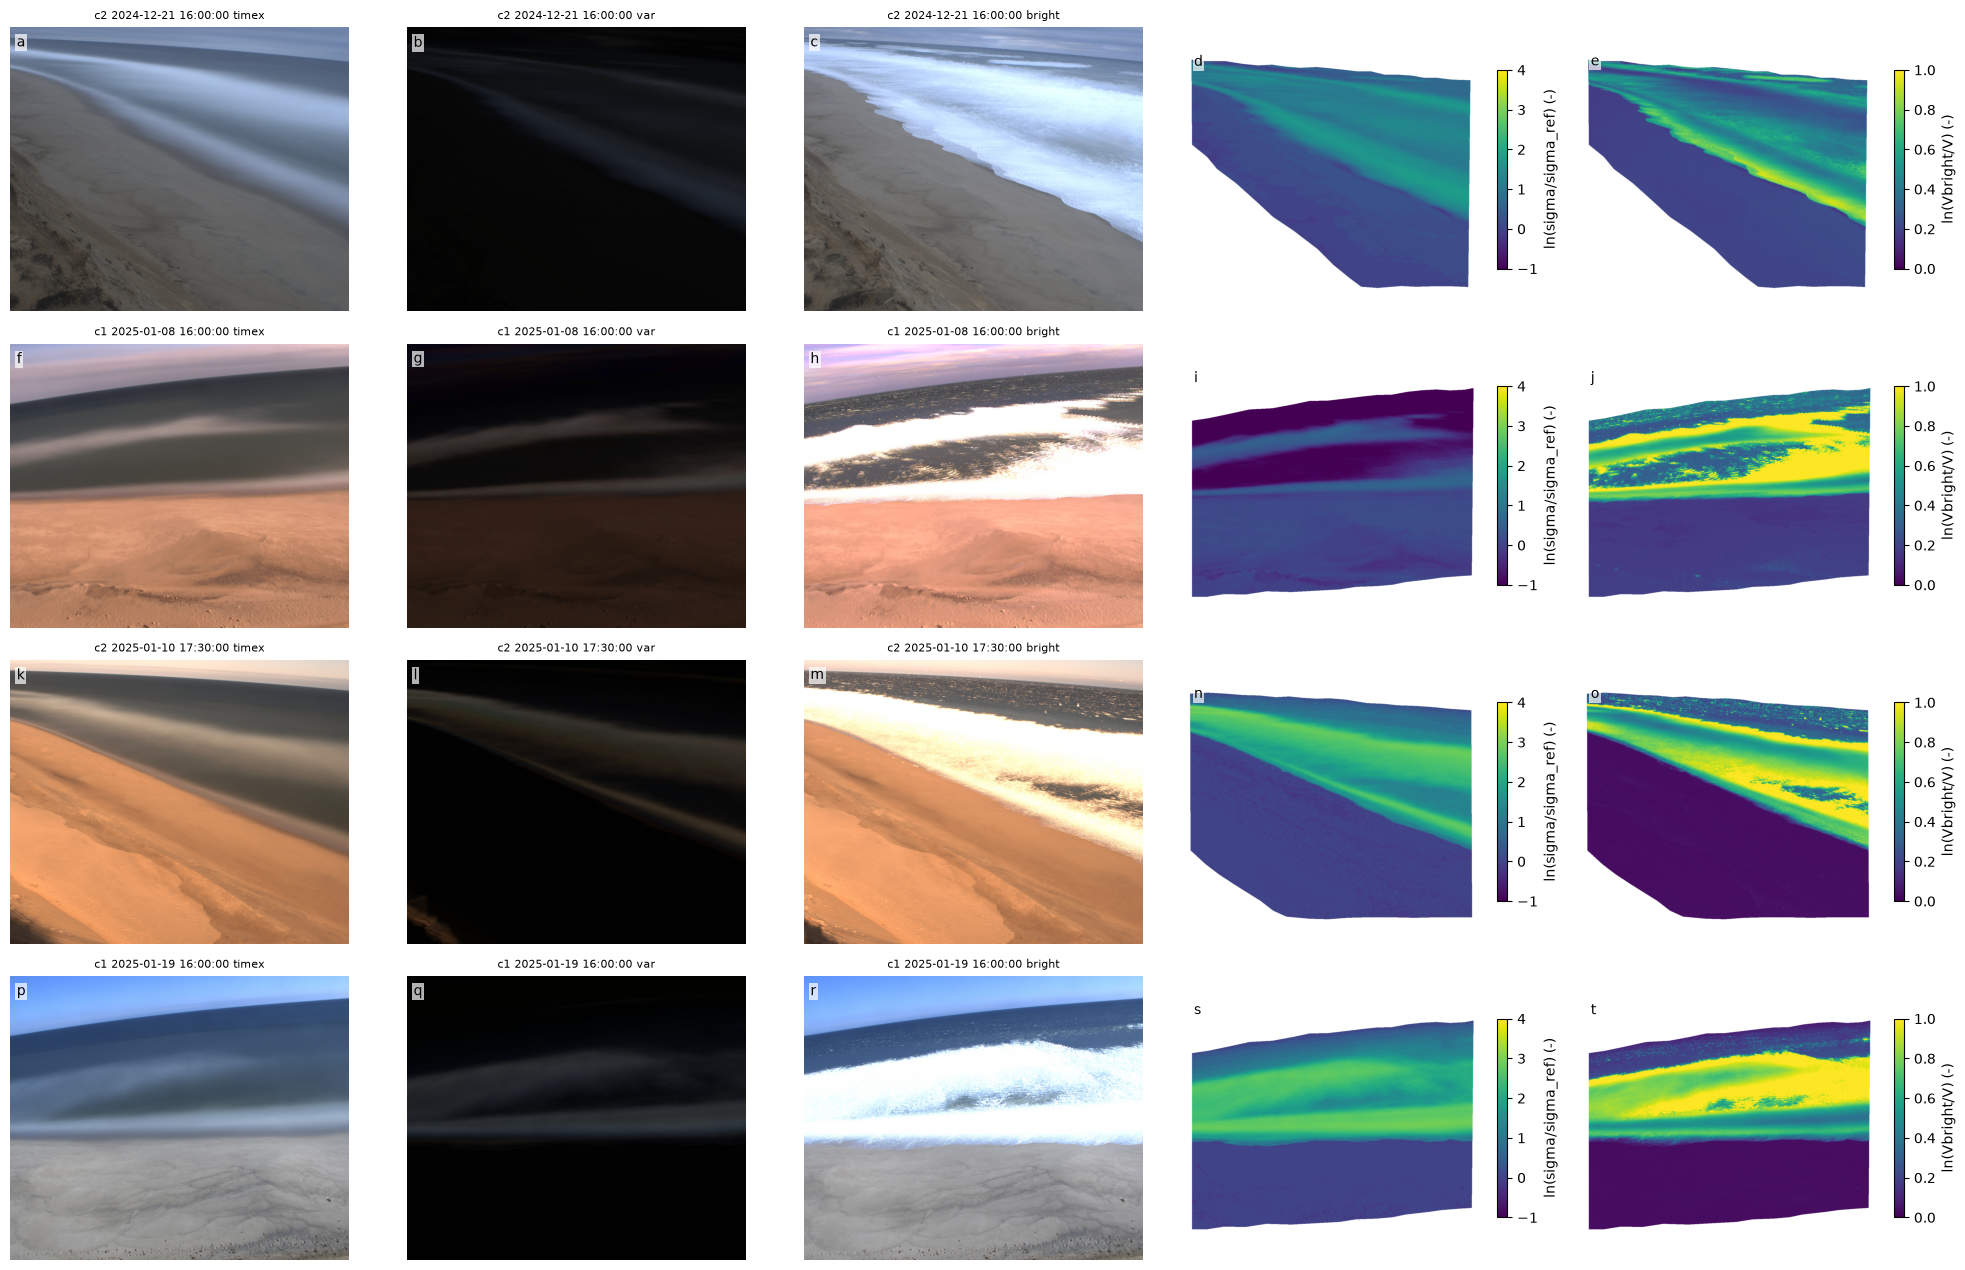

In [2]:
# timex, var and bright, and the var and bright features, for the first few label images
fig = mc.products_figure(FIG_DIR / 'class_products.png', imgs.head(4), prompts, COLOR)

In [3]:
%matplotlib qt
labels = mc.collect_labels(imgs, prompts, LABELS_CSV, ref, COLOR)

25 of 35 images to label
c1 2024-12-12 17:30:00 {'sand': 29, 'water': 23, 'whitewater': 19}
c1 2024-12-18 14:00:00 {'sand': 35, 'water': 27, 'whitewater': 10}
c1 2024-12-23 14:30:00 {'sand': 37, 'water': 37, 'whitewater': 32, 'snow': 25}
c1 2025-01-03 17:30:00 {'sand': 48, 'water': 28, 'whitewater': 3}
c1 2025-01-08 12:30:00 {'water': 30, 'sand': 29, 'whitewater': 23}
c1 2025-01-14 13:00:00 {'sand': 42, 'whitewater': 20, 'water': 13}
c1 2025-01-18 19:00:00 {'water': 50, 'sand': 39, 'whitewater': 18}
c1 2025-01-23 16:30:00 {'sand': 50, 'water': 42, 'whitewater': 30, 'snow': 24}
c1 2025-01-25 12:00:00 {'sand': 50, 'water': 32, 'snow': 21, 'whitewater': 17}
c1 2025-02-11 16:00:00 {'sand': 79, 'water': 50, 'snow': 34, 'whitewater': 21}
c1 2025-02-25 16:30:00 {'sand': 70, 'water': 58, 'whitewater': 19}
c1 2025-03-10 15:00:00 {'sand': 58, 'water': 37, 'whitewater': 5}
c2 2024-12-09 18:00:00 {'sand': 47, 'water': 26, 'whitewater': 25}
c2 2024-12-15 16:30:00 {'sand': 57, 'water': 31, 'whitewat

## Fit and check the model
Leave-one-image-out confusion matrix: each image is classified by a model fit to the others. What matters is dry
(sand, snow) versus wet (whitewater, water); confusion within those pairs does not move the waterline.

In [4]:
%matplotlib inline
labels = pd.read_csv(LABELS_CSV)
X, y, img_id = mc.sample_labels(labels, prompts, COLOR)
model = mc.fit(X, y, COLOR)
mc.save_model(MODEL_NPZ, model)
print(labels.groupby('cls').size().to_dict(), f'{len(np.unique(img_id))} images, {len(y)} pixels')
cm = mc.cross_validate(X, y, img_id, COLOR)
dry = cm.columns.isin(mc.DRY)
print('dry pixels called wet:', cm.loc[cm.index.isin(mc.DRY), ~dry].sum(1).round(3).to_dict(),
      ' wet pixels called dry:', cm.loc[~cm.index.isin(mc.DRY), dry].sum(1).round(3).to_dict())
cm.round(3)

{'sand': 2147, 'snow': 266, 'water': 1280, 'whitewater': 937} 46 images, 60190 pixels
dry pixels called wet: {'sand': 0.118, 'snow': 0.087}  wet pixels called dry: {'whitewater': 0.165, 'water': 0.146}


C:\Users\csherwood\AppData\Local\Temp\1\ipykernel_49588\2135719546.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  print('dry pixels called wet:', cm.loc[cm.index.isin(mc.DRY), ~dry].sum(1).round(3).to_dict(),
C:\Users\csherwood\AppData\Local\Temp\1\ipykernel_49588\2135719546.py:10: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ' wet pixels called dry:', cm.loc[~cm.index.isin(mc.DRY), dry].sum(1).round(3).to_dict())


predicted,sand,whitewater,water,snow
true,,,,
sand,0.710,0.076,0.043,0.172
whitewater,0.118,0.723,0.112,0.047
water,0.103,0.098,0.756,0.044
snow,0.294,0.083,0.004,0.619


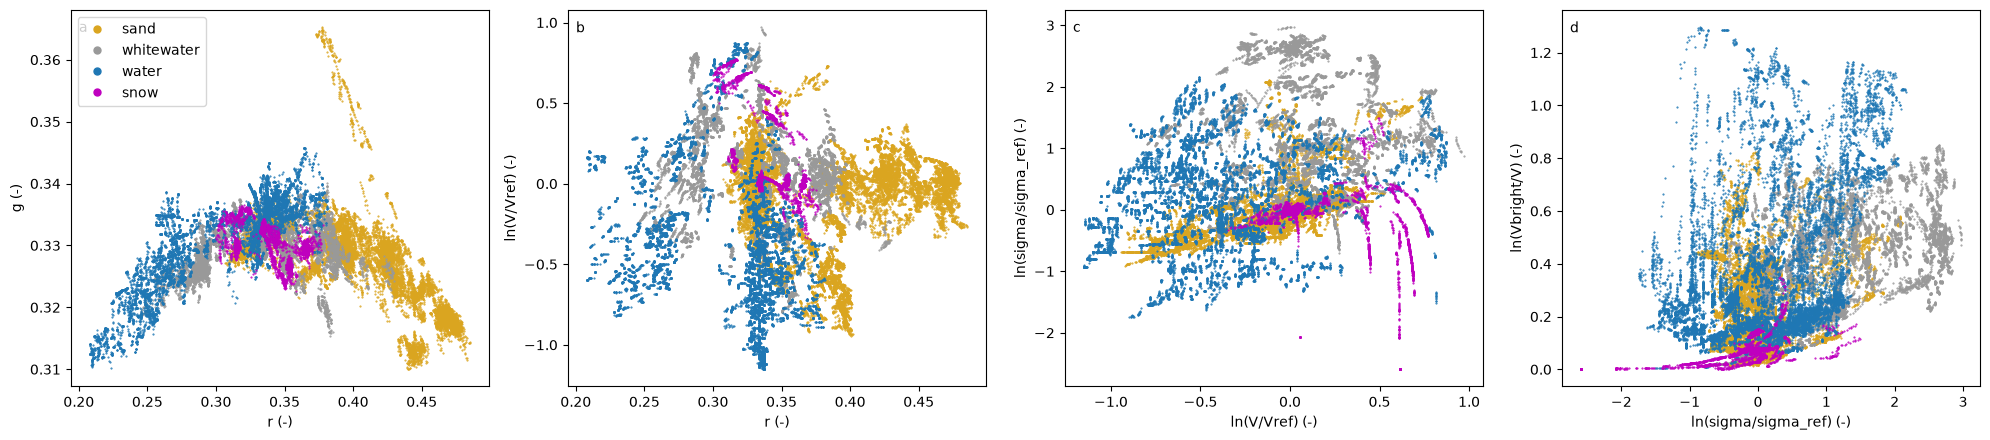

In [5]:
# features of the labeled pixels by class
names = mc.feature_names(COLOR['products'])
pairs = [(0, 1), (0, 2)] + ([(2, 3), (3, 4)] if len(names) == 5 else [])
fig, ax = plt.subplots(1, len(pairs), figsize=(5 * len(pairs), 4.5), squeeze=False)
for a, (i, j), l in zip(ax[0], pairs, 'abcd'):
    for c, col in zip(mc.CLASSES, ['goldenrod', '0.6', 'tab:blue', 'm']):
        a.plot(X[y == c, i], X[y == c, j], '.', ms=1, c=col, label=c)
    a.set_xlabel(f'{names[i]} (-)')
    a.set_ylabel(f'{names[j]} (-)')
    a.text(0.02, 0.97, l, transform=a.transAxes, va='top')
ax[0, 0].legend(markerscale=10)
fig.tight_layout()
fig.savefig(FIG_DIR / 'class_features.png', dpi=150)

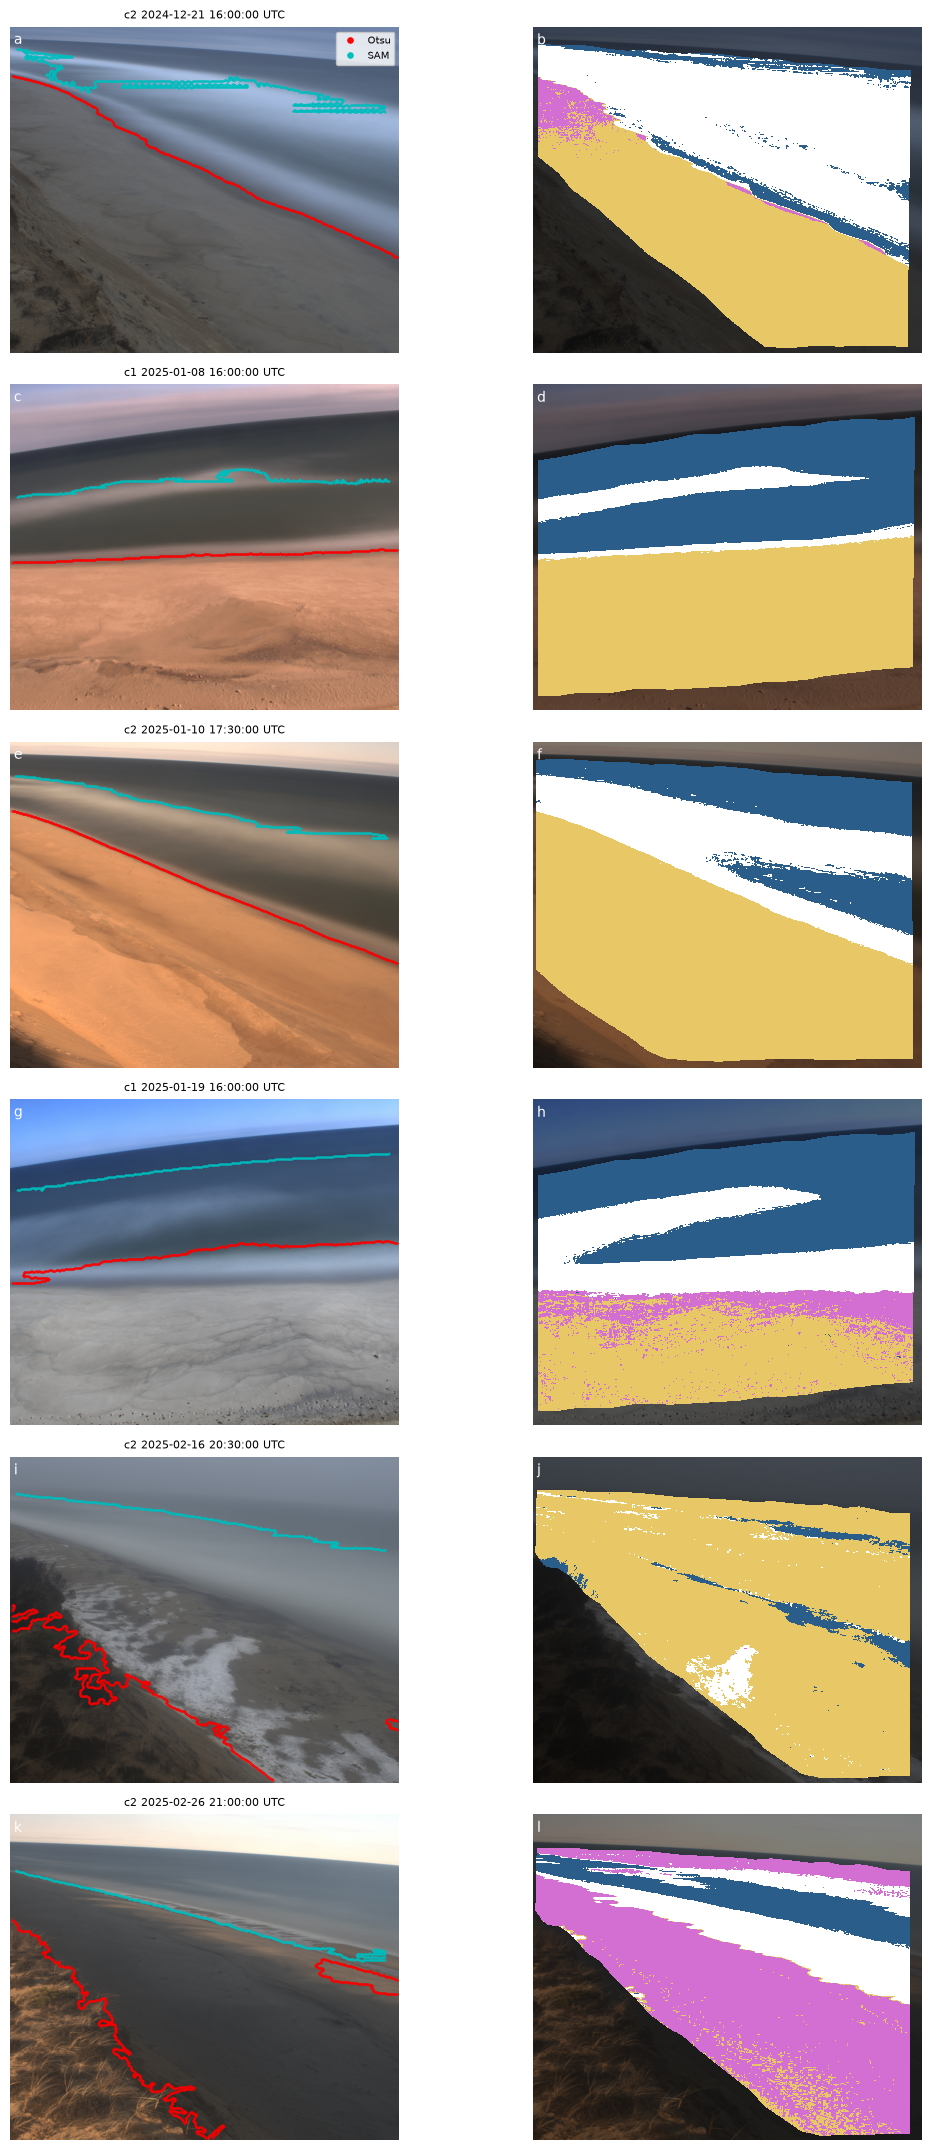

In [6]:
# classes on the worst images (or the first few labeled images): sand yellow, whitewater white, water blue, snow magenta
show = imgs[imgs.path.isin(worst)] if len(worst) else imgs.head(6)
fig = mc.class_figure(FIG_DIR / 'class_maps.png', show, prompts, model, ref, COLOR)

## Compare Otsu, class waterline, and SAM with class prompts
On a random sample (the same one `qc_waterlines.ipynb` used for SAM). Distances are between methods, not to
truth; the example figure shows which is right. Rerunning appends only new images; delete
`waterlines_px_class.csv` and `waterlines_px_sam_class.csv` after changing the labels or `COLOR`.

In [7]:
cand = scan[(scan.quality > 1) & scan.path.isin(wl_px.groups)]
paths = cand.path.sample(N_TEST, random_state=1)
mc.detect_all_color(scan, WL_CLASS_CSV, prompts, model, COLOR, paths)
pred = msam.load_sam(SAM_CKPT, SAM_MODEL)
info = msam.detect_all_sam(scan, CAL_DIR, WL_SAMC_CSV, pred, msam.SAM_CFG, paths, prompts=prompts, model=model, ccfg=COLOR)
info[['sam_score', 'color_iou', 'sam_npx']].describe()

60/60  2025-03-10 14:00:00
20/60  2025-01-17 20:00:00
40/60  2025-02-17 18:00:00
60/60  2025-03-10 14:00:00


,sam_score,color_iou,sam_npx
count,60.000000,60.000000,60.000000
mean,0.928360,0.711755,1605.083333
std,0.050837,0.332771,1066.538028
min,0.735168,0.000000,0.000000
25%,0.920858,0.618677,1164.750000
50%,0.941459,0.870300,1279.000000
75%,0.957532,0.945466,1867.500000
max,0.982669,0.987426,7380.000000


In [8]:
wl_cls = pd.read_csv(WL_CLASS_CSV).groupby('path')
wl_samc = pd.read_csv(WL_SAMC_CSV).groupby('path')
sets = {'otsu': wl_px, 'cls': wl_cls, 'samc': wl_samc} | ({'sam': wl_sam} if wl_sam is not None else {})
ok = [p for p in paths if all(p in g.groups for g in sets.values())]
pairs = [('otsu', 'cls'), ('cls', 'samc'), ('otsu', 'samc')] + ([('sam', 'samc')] if wl_sam is not None else [])
d = scan[['time', 'camera', 'H0', 'water_level', 'path']].set_index('path').loc[ok]
for a, b in pairs:
    c = msam.compare_waterlines(sets[a], sets[b], ok, (a, b)).set_index('path')
    d[f'{a}_{b}'] = c[[f'd_{a}_{b}_med', f'd_{b}_{a}_med']].max(1)
d.to_csv(OUT_DIR / 'waterline_compare_class.csv', float_format='%.2f')
d[[f'{a}_{b}' for a, b in pairs]].describe().round(1)

C:\Users\csherwood\AppData\Local\Temp\1\ipykernel_49588\4005432649.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  d[f'{a}_{b}'] = c[[f'd_{a}_{b}_med', f'd_{b}_{a}_med']].max(1)
C:\Users\csherwood\AppData\Local\Temp\1\ipykernel_49588\4005432649.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  d[f'{a}_{b}'] = c[[f'd_{a}_{b}_med', f'd_{b}_{a}_med']].max(1)
C:\Users\csherwood\AppData\Local\Temp\1\ipykernel_49588\4005432649.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  d[f'{a}_{b}'] = c[[f'd_{a}_{b}_med', f'd_{b}_{a}_med']].max(1)
C:\Users\csherwood\AppData\Local\Temp\1\ipykernel_49588\4005432649.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  d[f'{a}_{b}'] = c[[f'd_{a}_{b}_med', f'd_{b}_{a}_med']].max(1)


,otsu_cls,cls_samc,otsu_samc,sam_samc
count,54.0,54.0,56.0,56.0
mean,193.4,189.9,103.7,89.7
std,310.5,271.0,195.1,144.0
min,0.0,4.0,2.0,0.0
25%,16.4,26.0,9.7,4.0
50%,50.7,74.1,31.0,17.5
75%,198.5,207.3,108.6,103.9
max,1286.3,1428.8,1089.4,514.0


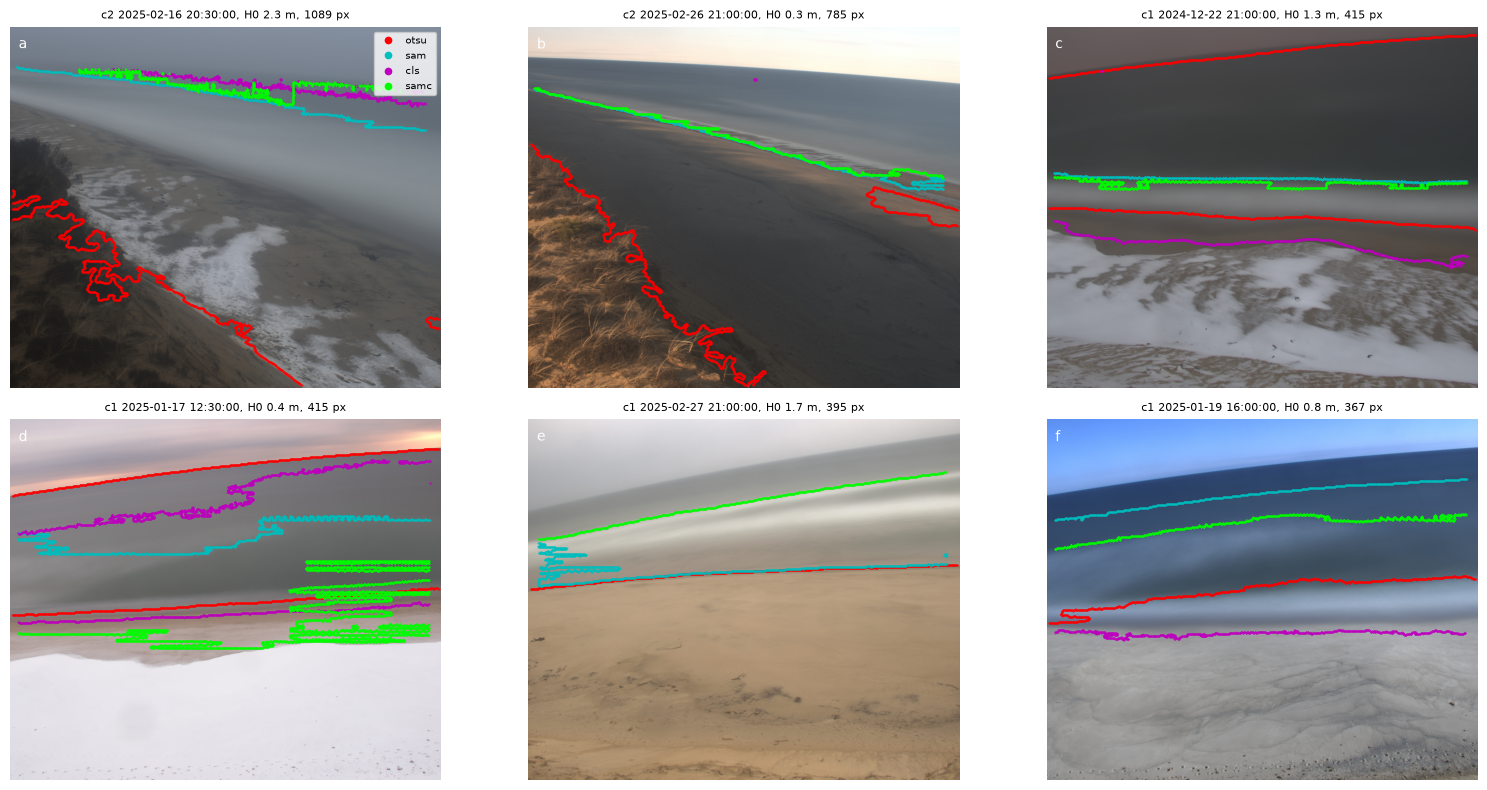

In [9]:
# the images where Otsu and SAM-with-classes disagree most, with all waterlines
ex = d.nlargest(6, 'otsu_samc')
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for a, (p, r), l in zip(ax.flat, ex.iterrows(), 'abcdef'):
    a.imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
    for name, c in [('otsu', 'r'), ('sam', 'c'), ('cls', 'm'), ('samc', 'lime')]:
        if name in sets and p in sets[name].groups:
            g = sets[name].get_group(p)
            a.plot(g.u, g.v, '.', c=c, ms=0.6, label=name)
    a.set_title(f'{r.camera} {r.time}, H0 {r.H0:.1f} m, {r.otsu_samc:.0f} px', fontsize=8)
    a.axis('off')
    a.text(0.02, 0.97, l, transform=a.transAxes, va='top', color='w')
ax.flat[0].legend(loc='upper right', markerscale=15, fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / 'waterline_compare_class_examples.jpg', dpi=120)

**Next:** if SAM with class prompts (`samc`) or the class waterline (`cls`) is consistently at the beach edge, run it
on all images (`paths=None`) and build DEMs from that waterline file with `make_dems.ipynb`.

**References**
- Plant, N.G., Aarninkhof, S.G.J., Turner, I.L., Kingston, K.S., 2007. The performance of shoreline detection
  models applied to video imagery. *Journal of Coastal Research* 23, 658–670.
- Vos, K., Harley, M.D., Splinter, K.D., Simmons, J.A., Turner, I.L., 2019a. Sub-annual to multi-decadal
  shoreline variability from publicly available satellite imagery. *Coastal Engineering* 150, 160–174.
- Vos, K., Splinter, K.D., Harley, M.D., Simmons, J.A., Turner, I.L., 2019b. CoastSat: A Google Earth
  Engine-enabled Python toolkit to extract shorelines from publicly available satellite imagery.
  *Environmental Modelling & Software* 122, 104528.
- Kirillov, A., et al., 2023. Segment Anything. *Proceedings of the IEEE/CVF International Conference on
  Computer Vision (ICCV)*, 4015–4026.